In [ ]:
import numpy as np

velocity = np.array([2000, 2800, 3500, 4000])
density = np.array ([2000, 2200, 2400, 2600])


acoustic_impedance = velocity * density

print(acoustic_impedance)


[ 4000000  6160000  8400000 10400000]


In [ ]:
Z1 = 4000000
Z2 = 6160000

R = (Z2-Z1)/(Z2+Z1)

print(round(R,2))

0.21


In [ ]:
acoustic_impedance = ([4000000, 6160000, 8400000, 10400000])

print(acoustic_impedance[1])


6160000


In [ ]:
Z1 = acoustic_impedance[0]
Z2 = acoustic_impedance[1]
R = (Z2-Z1)/(Z2+Z1)
print(round(R,2))

0.21


In [ ]:
Z1 = acoustic_impedance[1]
Z2 = acoustic_impedance[2]
R = (Z2-Z1)/(Z2+Z1)
print(round(R,2))

0.15


In [ ]:
#array slicing to avoid calculating each interface separately
import numpy as np
acoustic_impedance = np.array([4000000, 6160000, 8400000, 10400000])
print(acoustic_impedance[:-1])
print(acoustic_impedance[1:])

[4000000 6160000 8400000]
[ 6160000  8400000 10400000]


In [ ]:
Z1 = acoustic_impedance[:-1]
Z2 = acoustic_impedance[1:]

print("Z1", Z1)
print("Z2", Z2)

Z1 [4000000 6160000 8400000]
Z2 [ 6160000  8400000 10400000]


In [ ]:
R = (Z2-Z1)/(Z2+Z1)
print("Reflection_Coefficent", R)

Reflection_Coefficent [0.21259843 0.15384615 0.10638298]


## Lesson 13 - Synthetic Siesmogram


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

frequency = 25

time = np.arange(-0.1, 0.101, 0.001)

print(time)
print("number of samples", len(time))

[-1.00000000e-01 -9.90000000e-02 -9.80000000e-02 -9.70000000e-02
 -9.60000000e-02 -9.50000000e-02 -9.40000000e-02 -9.30000000e-02
 -9.20000000e-02 -9.10000000e-02 -9.00000000e-02 -8.90000000e-02
 -8.80000000e-02 -8.70000000e-02 -8.60000000e-02 -8.50000000e-02
 -8.40000000e-02 -8.30000000e-02 -8.20000000e-02 -8.10000000e-02
 -8.00000000e-02 -7.90000000e-02 -7.80000000e-02 -7.70000000e-02
 -7.60000000e-02 -7.50000000e-02 -7.40000000e-02 -7.30000000e-02
 -7.20000000e-02 -7.10000000e-02 -7.00000000e-02 -6.90000000e-02
 -6.80000000e-02 -6.70000000e-02 -6.60000000e-02 -6.50000000e-02
 -6.40000000e-02 -6.30000000e-02 -6.20000000e-02 -6.10000000e-02
 -6.00000000e-02 -5.90000000e-02 -5.80000000e-02 -5.70000000e-02
 -5.60000000e-02 -5.50000000e-02 -5.40000000e-02 -5.30000000e-02
 -5.20000000e-02 -5.10000000e-02 -5.00000000e-02 -4.90000000e-02
 -4.80000000e-02 -4.70000000e-02 -4.60000000e-02 -4.50000000e-02
 -4.40000000e-02 -4.30000000e-02 -4.20000000e-02 -4.10000000e-02
 -4.00000000e-02 -3.90000

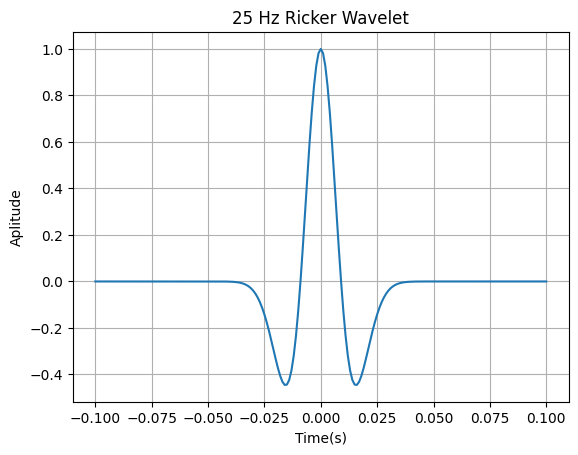

In [ ]:
a = (np.pi*frequency*time)**2
wavelet = (1-2*a)*np.exp(-a)

plt.plot(time,wavelet)
plt.xlabel("Time(s)")
plt.ylabel("Aplitude")
plt.title("25 Hz Ricker Wavelet")
plt.grid(True)
plt.show()

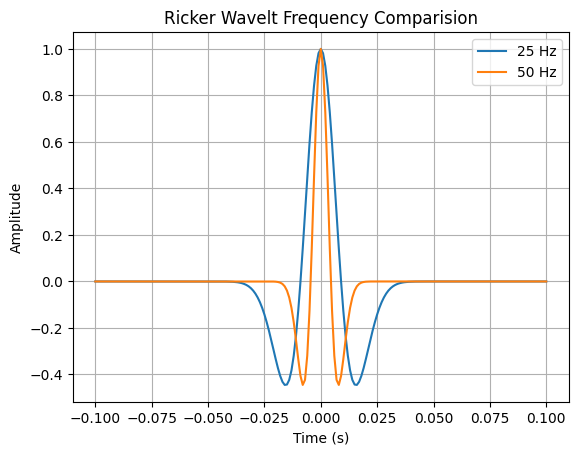

In [ ]:
a_50 = (np.pi*50*time)**2
wavelet_50 = (1-2*a_50)*np.exp(-a_50)

plt.plot(time, wavelet, label="25 Hz")
plt.plot(time, wavelet_50, label="50 Hz")

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Ricker Wavelt Frequency Comparision")
plt.legend()
plt.grid(True)
plt.savefig("Ricker wavelt frequency comparision.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#positioning the reflections at the calculated TWT
# cumulative twt calc from b4 minus the last sum
# R is reflection coefficients
reflection_times = cumulative_twt[:-1]

print(reflection_times)
print(R)

[0.5        1.         1.45714286]
[0.21259843 0.15384615 0.10638298]


In [ ]:
#recreating our 4 layer velocity model

thickness= np.array([500, 700, 800, 600])
velocity= np.array([2000, 2800, 3500, 4000])

#calculate the cumulative twt
interval_twt= (2*thickness)/velocity
cumulative_twt = np.cumsum(interval_twt)

print(cumulative_twt)

[0.5        1.         1.45714286 1.75714286]


In [ ]:
interval_twt = (2 * thickness) / velocity
cumulative_twt = np.cumsum(interval_twt)

print(cumulative_twt)

[0.5        1.         1.45714286 1.75714286]


In [ ]:
#so this creates a time axis from 0-2.001 seconds
#the range was chsosen from our model cause thats the time range of our model
trace_time = np.arange(0, 2.001, 0.001)
print ("Number of Samples:", len(trace_time))

Number of Samples: 2001


###### create an empty reflectivty array
###### np.zeros creates an array filled with zeros b/c our simplifed model has 3 interfaces everywhere else is assumed zero

In [ ]:

reflectivity = np.zeros(len(trace_time))
print(reflectivity)

[0. 0. 0. ... 0. 0. 0.]


In [ ]:
#We need Python to identify which array index corresponds to each reflection time.

reflectivity[500] = R[0]

print(reflectivity[500])

#Place the first reflection coefficient at 0.500 seconds

0.2125984251968504


In [ ]:
reflectivity[1000]=R[1]
print(reflectivity[1000])

0.15384615384615385


In [ ]:
index = int(round(reflection_times[2]/0.001))

print(index)

1457


In [ ]:
reflectivity[(index)]=R[2]
print(reflectivity[(index)])

0.10638297872340426


In [ ]:
print(reflectivity[500])
print(reflectivity[1000])
print(reflectivity[1457])

0.2125984251968504
0.15384615384615385
0.10638297872340426


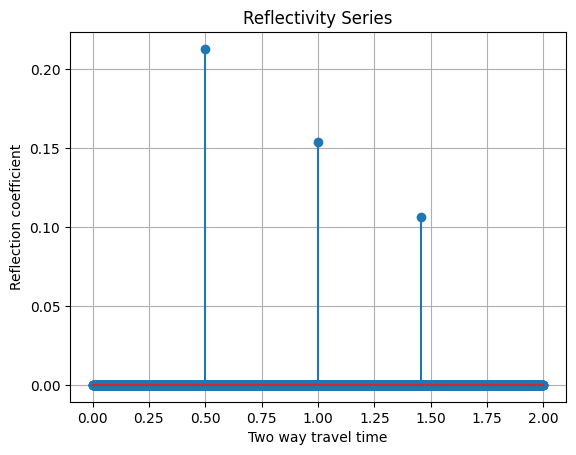

In [ ]:
#plotting te reflectivity series

plt.stem(trace_time, reflectivity)

plt.xlabel("Two way travel time")
plt.ylabel("Reflection coefficient")
plt.title("Reflectivity Series")
plt.grid(True)
plt.savefig("Reflectivity series.png", dpi=300, bbox_inches="tight")
plt.show()

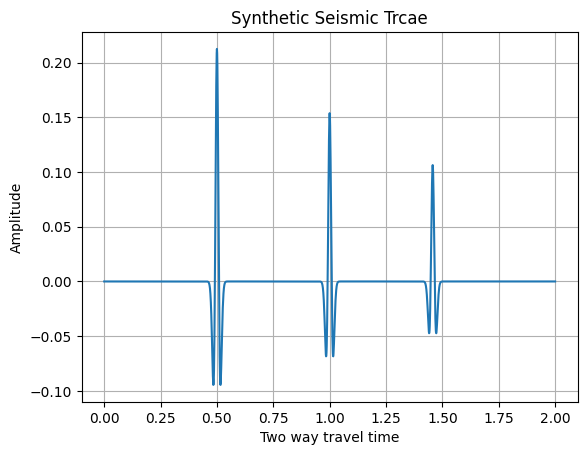

In [ ]:
# convolution
# reflectivity:when reflections occur and their strengths
# wavelet: our 25 Hz Ricker wavelet, which describes the shape of a seismic pulse

#1 combine them
import numpy as np

synthetic = np.convolve(reflectivity, wavelet, mode="same")
#2 plot
plt.plot(trace_time, synthetic)

plt.xlabel("Two way travel time")
plt.ylabel("Amplitude")
plt.title("Synthetic Seismic Trcae")
plt.grid(True)
plt.savefig("Synthetic_Seismic_Trace.png", dpi=300, bbox_inches="tight")
plt.show()
